# Hierarchical Model Comparison: Rescorla-Wagner (Valence) vs. Kalman Filter (Non-GAD)
This notebook fits and compares two alternative hierarchical cognitive models on the four-armed bandit task behavioral data:
1. **Rescorla-Wagner (Valence) Model:** Uses separate positive and negative learning rates ($\alpha_{pos}, \alpha_{neg}$) and choice stochasticity (inverse temperature $\beta$) for each subject.
2. **Kalman Filter (Non-GAD) Model:** Uses subject-level process noise $Q$ (drift variance), observation noise $R$ (measurement noise), and choice stochasticity $\beta$ (all log-normally distributed across subjects).

We draw posterior samples using the JAX-backed NUTS sampler (`numpyro`) and run Leave-One-Out cross-validation (LOO) via ArviZ to determine which model better explains the behavioral choices.


In [1]:
import pandas as pd
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import matplotlib.pyplot as plt
import arviz as az
import warnings

from learning_functions import prepare_vectorized_bandit_data, step_m2_vec, step_kalman_vec, add_bernoulli_ll

warnings.filterwarnings('ignore')


In [2]:
# Load and vectorize data into (max_t, n_sub) subject-batched tensors
file_path = '../data/allsubs_combined.csv'
df_raw = pd.read_csv(file_path).dropna(subset=['ChoiceKey']).reset_index(drop=True).copy()

stim_map = {'W1': 0, 'W2': 1, 'L1': 2, 'L2': 3}
df_raw['LeftID_int'] = df_raw['LeftID'].map(stim_map)
df_raw['RightID_int'] = df_raw['RightID'].map(stim_map)
df_raw['ChosenID_int'] = df_raw['ChosenID'].map(stim_map)
df_raw['Choice'] = (df_raw['ChoiceKey'] - 1).astype(int)
df_raw['RewardScaled'] = df_raw['TrialPoints'] / 30.0

vdata = prepare_vectorized_bandit_data(df_raw)
df = vdata['df']
n_sub = vdata['n_sub']
unique_subs = vdata['unique_subs']

print(f"Total subjects: {n_sub}")
print(f"Total trials across all subjects: {len(df)} (Vectorized scan length: {vdata['max_t']} steps)")


Total subjects: 67
Total trials across all subjects: 6520 (Vectorized scan length: 100 steps)


In [3]:
# Using vectorized step_m2_vec and step_kalman_vec from learning_functions.py


In [4]:
def make_hierarchical_alpha(name, n_sub):
    mu = pm.Normal(f'{name}_mu', mu=0, sigma=1.5)
    sigma = pm.HalfNormal(f'{name}_sigma', sigma=1.0)
    raw = pm.Normal(f'{name}_raw', mu=0, sigma=1, shape=n_sub)
    return pm.Deterministic(name, pm.math.invlogit(mu + raw * sigma))

def make_hierarchical_beta(name, n_sub):
    mu = pm.Normal(f'{name}_mu', mu=0, sigma=2.0)
    sigma = pm.HalfNormal(f'{name}_sigma', sigma=1.0)
    raw = pm.Normal(f'{name}_raw', mu=0, sigma=1, shape=n_sub)
    return pm.Deterministic(name, pm.math.exp(mu + raw * sigma))

def build_rw_valence_model(vdata):
    n_sub, t_idx, s_idx = vdata['n_sub'], vdata['t_idx'], vdata['s_idx']
    with pm.Model() as rw_model:
        alpha_pos = make_hierarchical_alpha('alpha_pos', n_sub)
        alpha_neg = make_hierarchical_alpha('alpha_neg', n_sub)
        beta = make_hierarchical_beta('beta', n_sub)
        Q_init = pt.zeros((n_sub, 4))
        results = pytensor.scan(
            fn=step_m2_vec,
            sequences=[
                pt.as_tensor_variable(vdata['left_oh']),
                pt.as_tensor_variable(vdata['right_oh']),
                pt.as_tensor_variable(vdata['chosen_oh']),
                pt.as_tensor_variable(vdata['rew_mat']),
            ],
            outputs_info=[Q_init, None, None, None],
            non_sequences=[alpha_pos, alpha_neg],
            strict=True,
            return_updates=False
        )
        q_left_seq = results[1][t_idx, s_idx]
        q_right_seq = results[2][t_idx, s_idx]
        p_right_raw = pm.math.sigmoid(beta[s_idx] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        pm.Bernoulli('choice_obs', p=p_right, observed=vdata['df']['Choice'].values)
    return rw_model

def build_kalman_model(vdata):
    n_sub, t_idx, s_idx = vdata['n_sub'], vdata['t_idx'], vdata['s_idx']
    with pm.Model() as kf_model:
        mu_Q_log = pm.Normal('mu_Q_log', mu=-2, sigma=1)
        sigma_Q = pm.HalfNormal('sigma_Q', sigma=1.0)
        Q_raw = pm.Normal('Q_raw', mu=0, sigma=1, shape=n_sub)
        Q_sub = pm.Deterministic('Q_sub', pm.math.exp(mu_Q_log + Q_raw * sigma_Q))
        
        mu_R_log = pm.Normal('mu_R_log', mu=-1, sigma=1)
        sigma_R = pm.HalfNormal('sigma_R', sigma=1.0)
        R_raw = pm.Normal('R_raw', mu=0, sigma=1, shape=n_sub)
        R_sub = pm.Deterministic('R_sub', pm.math.exp(mu_R_log + R_raw * sigma_R))
        
        mu_beta_log = pm.Normal('mu_beta_log', mu=1, sigma=1)
        sigma_beta = pm.HalfNormal('sigma_beta', sigma=0.5)
        beta_raw = pm.Normal('beta_raw', mu=0, sigma=1, shape=n_sub)
        beta = pm.Deterministic('beta', pm.math.exp(mu_beta_log + beta_raw * sigma_beta))
        
        mu_init = pt.zeros((n_sub, 4)) + 0.5
        sigma2_init = pt.ones((n_sub, 4)) * 1.0
        
        results = pytensor.scan(
            fn=step_kalman_vec,
            sequences=[
                pt.as_tensor_variable(vdata['left_oh']),
                pt.as_tensor_variable(vdata['right_oh']),
                pt.as_tensor_variable(vdata['chosen_oh']),
                pt.as_tensor_variable(vdata['rew_mat']),
                pt.as_tensor_variable(vdata['valid_mat']),
            ],
            outputs_info=[mu_init, sigma2_init, None, None],
            non_sequences=[Q_sub, R_sub],
            strict=True,
            return_updates=False
        )
        q_left_seq = results[2][t_idx, s_idx]
        q_right_seq = results[3][t_idx, s_idx]
        p_right_raw = pm.math.sigmoid(beta[s_idx] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        pm.Bernoulli('choice_obs', p=p_right, observed=vdata['df']['Choice'].values)
    return kf_model


In [5]:
y_obs = df['Choice'].values

print("--- Fit and Sample Rescorla-Wagner (Valence) Model (nutpie, PyMC 6) ---")
m_rw = build_rw_valence_model(vdata)
with m_rw:
    idata_rw = pm.sample(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=True)
    add_bernoulli_ll(idata_rw, y_obs)

print("\n--- Fit and Sample Kalman Filter (Non-GAD) Model (nutpie, PyMC 6) ---")
m_kf = build_kalman_model(vdata)
with m_kf:
    idata_kf = pm.sample(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=True)
    add_bernoulli_ll(idata_kf, y_obs)


--- Fit and Sample Rescorla-Wagner (Valence) Model (nutpie, PyMC 6) ---


NUTS[nutpie]: [alpha_pos_mu, alpha_pos_sigma, alpha_pos_raw, alpha_neg_mu, alpha_neg_sigma, alpha_neg_raw, beta_mu, beta_sigma, beta_raw]


Output()


--- Fit and Sample Kalman Filter (Non-GAD) Model (nutpie, PyMC 6) ---


NUTS[nutpie]: [mu_Q_log, sigma_Q, Q_raw, mu_R_log, sigma_R, R_raw, mu_beta_log, sigma_beta, beta_raw]


Output()

MODEL COMPARISON (LOO)
                           rank    elpd      p  elpd_diff  weight    se   dse  \
Rescorla-Wagner (Valence)     0 -2910.0  150.3        0.0    0.78  44.0   0.0   
Kalman Filter (Non-GAD)       1 -3020.0  138.4     -110.0    0.22  42.0  22.0   

                           warning  
Rescorla-Wagner (Valence)     True  
Kalman Filter (Non-GAD)       True  



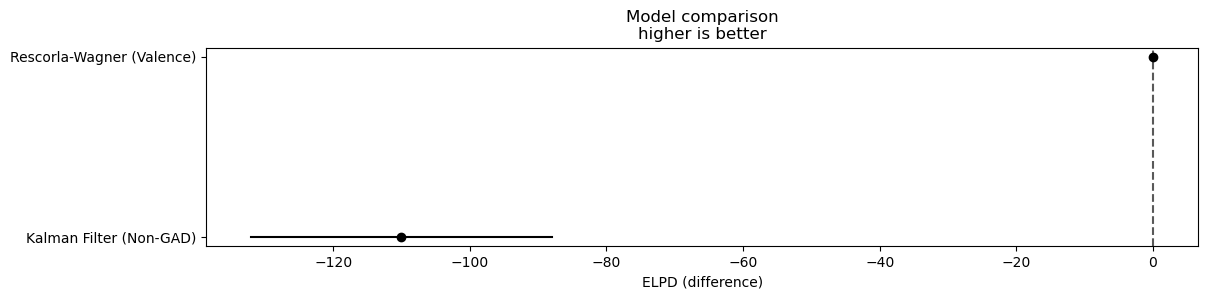

In [6]:
# Run ArviZ comparison
comp_dict = {
    "Rescorla-Wagner (Valence)": idata_rw,
    "Kalman Filter (Non-GAD)": idata_kf
}

comp = az.compare(comp_dict)
print("==================================================")
print("MODEL COMPARISON (LOO)")
print("==================================================")
print(comp)
print("==================================================\n")

az.plot_compare(comp)
plt.show()
